# Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels,angle_between_vectors, get_segment_borders, get_segment_vectors
from Util.pulltest_util import fill_short_runs

In [2]:
recording_name = "tug2"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

fps = 100
# q_cut_1 = 800 #tug1
# s_cut_1 = 950 #tug1
# BASELINE_DURATION = 2 # seconds

q_cut_1 = 900 #tug2
s_cut_1 = 1000 #tug2
BASELINE_DURATION = 3 # seconds
q_cut_2 = q_cut_1 + len(stereo_keypoints) - s_cut_1 #TODO: this only works if the qualisys recoridng is longer than the stereo

baseline_end = BASELINE_DURATION * fps


qualisys_keypoints = qualisys_keypoints[q_cut_1:q_cut_2,:,:]
stereo_keypoints = stereo_keypoints[s_cut_1:,:,:]

loaded data from: data\tug2\tug2_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\tug2\tug2_qualisys.npz with keys: ['labels', 'keypoints']


# segmentation

In [6]:
def get_keypoint_position_mask(
    keypoint: np.ndarray,
    baseline_end: float,
    direction: str,
    min_state_length: float,
    threshold: float,
    max_percentile:int
):
    """
    Normalizes 1D keypoint coords, creates a mask indicating the position being close to the max (up, side) or min (down) of the whole recording.
    Assumes the coordinate rises after the baseline.
    """
    position = keypoint
    position_baseline = np.nanmean(position[: int(baseline_end)])
    position_baseline_diff = position - position_baseline
    position_normalized = position_baseline_diff / np.nanpercentile(position_baseline_diff, max_percentile)

    match direction:
        case "up" :
            mask = position_normalized > 1 - threshold
            mask = fill_short_runs(mask, value=0, min_length=min_state_length)
        case "down" | "side":
            mask = position_normalized < threshold
            mask = fill_short_runs(mask, value=1, min_length=min_state_length)
            mask = fill_short_runs(mask, value=0, min_length=min_state_length)

    
    # mask = fill_short_runs(mask, value=1, min_length=min_state_length)
    return mask, position_normalized


def get_trunk_angle_and_movement_mask(
    keypoints: np.ndarray,
    labels: list,
    baseline_end: float,
    threshold: float,
    min_lean_time: float
):
    """
    Calculates the angle of the trunk vectors (mid_hip -> mid_shoulder) compared to their baseline mean (sitting).
    Also creates a movement mask indicating when the lean angle is less than threshold.

    Args:
        keypoints: keypoint data (n_frames, n_kpts, n_dims)
        labels: labels for the keypoints
        baseline_end: end of the baseline period (in samples)
        threshold: limit (in degrees) above which leaning/movement is detected
        min_lean_time: duration of time (in seconds) below which leaning/movement is considered noise
    """
    trunk_vectors = get_segment_vectors(
        keypoints, labels, start_kpt_name="mid_hip", end_kpt_name="mid_shoulder"
    )
    trunk_vector_baseline = np.nanmean(trunk_vectors[:baseline_end], axis=0)
    trunk_angles = np.array(
        [
            angle_between_vectors(trunk_vector, trunk_vector_baseline)
            for trunk_vector in trunk_vectors
        ]
    )
    trunk_angle_baseline = np.nanmean(trunk_angles[:baseline_end])
    leaning_mask = (trunk_angles - trunk_angle_baseline) < threshold
    # leaning_mask = fill_short_runs(leaning_mask, value=0, min_length=min_lean_time).astype(
    #     bool
    # )
    leaning_mask = fill_short_runs(leaning_mask, value=1, min_length=min_lean_time).astype(
        bool
    )

    return trunk_angles, leaning_mask




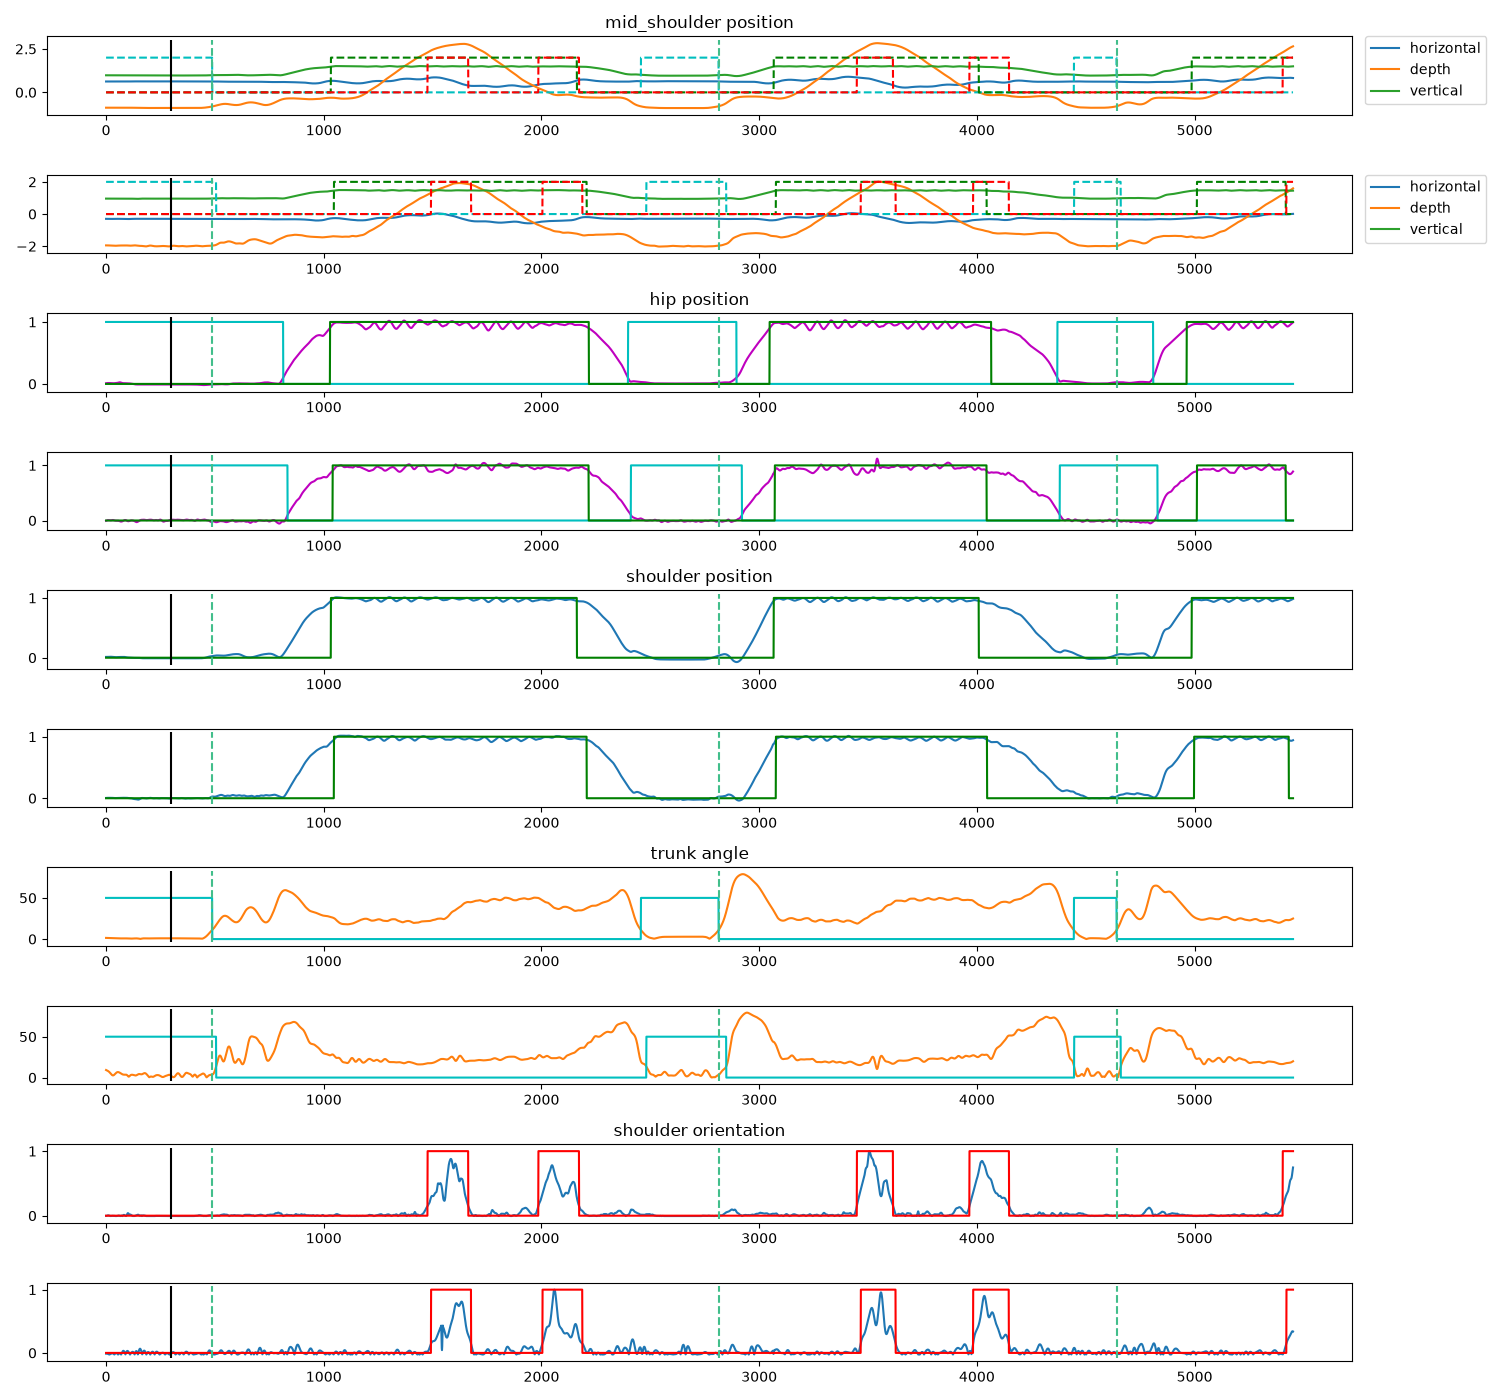

In [8]:
# hip position
MIN_SIT_STAND_DURATION = 0.75 # seconds
HIP_DOWN_THR = 0.1  # fraction (normalized)
HIP_UP_THR = 0.1  # fraction (normalized)
qualisys_hip_vertical = qualisys_keypoints[:, qualisys_labels.index('mid_hip'),2]
qualisys_hip_down, _ = get_keypoint_position_mask(qualisys_hip_vertical, baseline_end, "down", MIN_SIT_STAND_DURATION*fps, HIP_DOWN_THR,95)
qualisys_hip_up, qualisys_hip_vertical = get_keypoint_position_mask(qualisys_hip_vertical, baseline_end, "up", MIN_SIT_STAND_DURATION*fps, HIP_UP_THR,95)

stereo_hip_vertical = stereo_keypoints[:, stereo_labels.index('mid_hip'),2]
stereo_hip_down, _ = get_keypoint_position_mask(stereo_hip_vertical, baseline_end, "down", MIN_SIT_STAND_DURATION*fps, HIP_DOWN_THR,95)
stereo_hip_up, stereo_hip_vertical = get_keypoint_position_mask(stereo_hip_vertical, baseline_end, "up", MIN_SIT_STAND_DURATION*fps, HIP_UP_THR,95)


# shoulder position
SHOULDER_UP_THR = 0.05
qualisys_shoulder_vertical = qualisys_keypoints[:, qualisys_labels.index('mid_shoulder'),2]
qualisys_shoulder_up, qualisys_shoulder_vertical = get_keypoint_position_mask(qualisys_shoulder_vertical,baseline_end,"up",MIN_SIT_STAND_DURATION*fps,SHOULDER_UP_THR,95)

stereo_shoulder_vertical = stereo_keypoints[:, stereo_labels.index('mid_shoulder'),2]
stereo_shoulder_up, stereo_shoulder_vertical = get_keypoint_position_mask(stereo_shoulder_vertical, baseline_end, "up", MIN_SIT_STAND_DURATION*fps, SHOULDER_UP_THR,95)


# lean angle
TRUNK_ANGLE_THR = 10  # degrees TODO: assuming they return to a sitting position within thr degrees of baseline
MIN_LEAN_TIME = 1  # sec
qualisys_trunk_angles, qualisys_leaning_mask = get_trunk_angle_and_movement_mask(qualisys_keypoints, qualisys_labels, baseline_end, TRUNK_ANGLE_THR, MIN_LEAN_TIME*fps)
stereo_trunk_angles, stereo_leaning_mask = get_trunk_angle_and_movement_mask(stereo_keypoints, stereo_labels, baseline_end, TRUNK_ANGLE_THR, MIN_LEAN_TIME*fps)


# turning
TURN_THR = 0.15
MIN_TURN_DURATION = 0.5 # seconds
qualisys_shoulder_horizontal = np.abs(np.gradient(get_segment_vectors(qualisys_keypoints, qualisys_labels, start_kpt_name='left_shoulder', end_kpt_name='right_shoulder')[:,0]))
qualisys_straight_mask, qualisys_shoulder_horizontal = get_keypoint_position_mask(qualisys_shoulder_horizontal,baseline_end,"side",MIN_TURN_DURATION*fps,TURN_THR,100)

stereo_shoulder_horizontal = np.abs(np.gradient(get_segment_vectors(stereo_keypoints, stereo_labels, start_kpt_name='left_shoulder', end_kpt_name='right_shoulder')[:,0]))
stereo_straight_mask, stereo_shoulder_horizontal = get_keypoint_position_mask(stereo_shoulder_horizontal,baseline_end,"side",MIN_TURN_DURATION*fps,TURN_THR,100)


# final masks
qualisys_sit_mask = qualisys_hip_down & qualisys_leaning_mask # hips down and trunk straight
qualisys_stand_mask = qualisys_hip_up & qualisys_shoulder_up  # hips up and shoulders up
qualisys_turn_mask = ~qualisys_straight_mask                  # shoulders in line (horizontal)

stereo_sit_mask = stereo_hip_down & stereo_leaning_mask
stereo_stand_mask = stereo_hip_up & stereo_shoulder_up 
stereo_turn_mask = ~stereo_straight_mask

qualisys_tugs = get_segment_borders(qualisys_sit_mask)

if True:
    plt.close("all")
    fig, axs = plt.subplots(10, 1, figsize=(15, 14))

    axs[0].set_title("mid_shoulder position")
    axs[0].plot(qualisys_keypoints[:, qualisys_labels.index("mid_shoulder"), :],label=["horizontal", "depth", "vertical"])
    axs[0].plot(qualisys_sit_mask * 2, "c--")
    axs[0].plot(qualisys_stand_mask*2, 'g--')
    axs[0].plot(qualisys_turn_mask*2,'r--')
    axs[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
    axs[1].plot(stereo_keypoints[:, stereo_labels.index("mid_shoulder"), :],label=["horizontal", "depth", "vertical"])
    axs[1].plot(stereo_sit_mask * 2, "c--")
    axs[1].plot(stereo_stand_mask*2, 'g--')
    axs[1].plot(stereo_turn_mask*2,'r--')
    axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

    axs[2].set_title("hip position")
    axs[2].plot(qualisys_hip_vertical, "m")
    axs[2].plot(qualisys_hip_down, "c")
    axs[2].plot(qualisys_hip_up, "g")
    axs[3].plot(stereo_hip_vertical, "m")
    axs[3].plot(stereo_hip_down, "c")
    axs[3].plot(stereo_hip_up, "g")

    axs[4].set_title("shoulder position")
    axs[4].plot(qualisys_shoulder_vertical)
    axs[4].plot(qualisys_shoulder_up, "g")
    axs[5].plot(stereo_shoulder_vertical)
    axs[5].plot(stereo_shoulder_up, "g")

    axs[6].set_title("trunk angle")
    axs[6].plot(qualisys_trunk_angles, "tab:orange")
    axs[6].plot(qualisys_leaning_mask * 50, "c")
    axs[7].plot(stereo_trunk_angles, "tab:orange")
    axs[7].plot(stereo_leaning_mask * 50, "c")

    axs[8].set_title('shoulder orientation')
    axs[8].plot(qualisys_shoulder_horizontal)
    axs[8].plot(qualisys_turn_mask, 'r')
    axs[9].plot(stereo_shoulder_horizontal)
    axs[9].plot(stereo_turn_mask,'r')


    for ax in axs:
        y_min, y_max = ax.get_ylim()
        ax.vlines(baseline_end, y_min, y_max, "k")
        for segment_start, segment_end in qualisys_tugs:
            # ax.vlines(segment_start, y_min, y_max, color="#923030", linestyle='--')
            ax.vlines(segment_end, y_min, y_max, color="#42BE8B", linestyle='--')
        # ax.vlines(5280, y_min, y_max)

    plt.tight_layout()

# parameters

In [13]:
qualisys_TUGs = []
qualisys_recording_segments = get_segment_borders(qualisys_sit_mask)
for idx, (_, current_segment_end) in enumerate(qualisys_recording_segments):
    if idx < len(qualisys_recording_segments)-1:
        next_segment_start = qualisys_recording_segments[idx+1][0]
        print(idx, current_segment_end, next_segment_start)
        qualisys_TUGs.append(TimedUpAndGo(start=current_segment_end, end=next_segment_start))
qualisys_TUGs

0 488 2457
1 2814 4446


[TUG(start=488, end=2457), TUG(start=2814, end=4446)]

In [14]:
qualisys_TUGs = [
    TimedUpAndGo(start=current_segment_end, end=next_segment_start)
    for (_, current_segment_end), (next_segment_start, _) in zip(qualisys_recording_segments, qualisys_recording_segments[1:])
]
qualisys_TUGs

[TUG(start=488, end=2457), TUG(start=2814, end=4446)]

In [4]:
class TimedUpAndGo:
    def __init__(self, start, end):
        self.start = start
        self.end = end

    def __repr__(self):
        # short form, used when a list of TUGs is displayed
        return f"TUG(start={self.start}, end={self.end})"

MIN_SIT_STAND_DURATION = 0.75 # seconds
HIP_DOWN_THR = 0.1  # fraction (normalized)
HIP_UP_THR = 0.1  # fraction (normalized)
SHOULDER_UP_THR = 0.05
TRUNK_ANGLE_THR = 10  # degrees TODO: assuming they return to a sitting position within thr degrees of baseline
MIN_LEAN_TIME = 1  # sec
TURN_THR = 0.15
MIN_TURN_DURATION = 0.5 # seconds

class TimedUpAndGoRecording:
    def __init__(self, system, keypoints, labels, fps=100):
        self.system = system
        self.keypoints = keypoints
        self.labels = labels
        self.fps = fps
        self.baseline_end = int(BASELINE_DURATION * self.fps)
        self.sit_mask = None
        self.stand_mask = None
        self.turn_mask = None
        self.tugs: list[TimedUpAndGo] = []

    def segment_tugs(self):
        # hips
        hip_vertical = self.keypoints[:, self.labels.index('mid_hip'),2]
        hip_down, _ = get_keypoint_position_mask(hip_vertical, self.baseline_end, "down", MIN_SIT_STAND_DURATION*self.fps, HIP_DOWN_THR,95)
        hip_up, hip_vertical = get_keypoint_position_mask(hip_vertical, self.baseline_end, "up", MIN_SIT_STAND_DURATION*self.fps, HIP_UP_THR,95)
        # shoulders
        shoulder_vertical = self.keypoints[:, self.labels.index('mid_shoulder'),2]
        shoulder_up, shoulder_vertical = get_keypoint_position_mask(shoulder_vertical,self.baseline_end,"up",MIN_SIT_STAND_DURATION*self.fps,SHOULDER_UP_THR,95)
        # tunk angles
        self.trunk_angles, leaning_mask = get_trunk_angle_and_movement_mask(self.keypoints, self.labels, self.baseline_end, TRUNK_ANGLE_THR, MIN_LEAN_TIME*self.fps)
        # turninig
        shoulder_horizontal_velocity = np.abs(np.gradient(get_segment_vectors(self.keypoints, self.labels, start_kpt_name='left_shoulder', end_kpt_name='right_shoulder')[:,0]))
        straight_mask, shoulder_horizontal_velocity = get_keypoint_position_mask(shoulder_horizontal_velocity,self.baseline_end,"side",MIN_TURN_DURATION*self.fps,TURN_THR,100)

        # final masks
        self.sit_mask = hip_down & leaning_mask # hips down and trunk straight
        self.stand_mask = hip_up & shoulder_up  # hips up and shoulders up
        self.turn_mask = ~straight_mask         # shoulders in line (horizontal)

        segment_borders = get_segment_borders(self.sit_mask)
        self.tugs = [
            TimedUpAndGo(start=current_segment_end, end=next_segment_start)
            for (_, current_segment_end), (next_segment_start, _) in zip(segment_borders, segment_borders[1:])
        ]



In [5]:
Q = TimedUpAndGoRecording(system='qualisys', keypoints=qualisys_keypoints, labels=qualisys_labels,fps=100)
Q.segment_tugs()
Q.tugs

[TUG(start=488, end=2457), TUG(start=2814, end=4446)]